Global Best Position found: [2.70502498e-09 1.42912326e-09]
Global Best Score found: 0.0


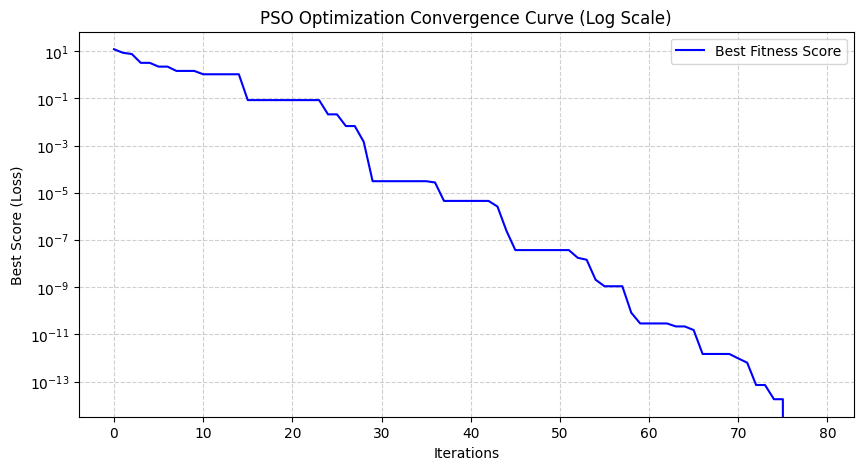

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def rastrigin(x):

    A = 10
    return A * len(x) + np.sum(x**2 - A * np.cos(2 * np.pi * x))

class Particle:
    def __init__(self, bounds):
        self.position = np.array([np.random.uniform(b[0], b[1]) for b in bounds])
        self.velocity = np.array([np.random.uniform(-abs(b[1]-b[0])/10, abs(b[1]-b[0])/10) for b in bounds])
        self.best_position = np.copy(self.position)
        self.best_score = float('inf')

class PSO:
    def __init__(self, objective_func, bounds, num_particles=30, max_iter=100, w=0.5, c1=1.5, c2=1.5):
        self.objective_func = objective_func
        self.bounds = bounds
        self.num_particles = num_particles
        self.max_iter = max_iter
        self.w = w
        self.c1 = c1
        self.c2 = c2

        self.particles = [Particle(bounds) for _ in range(num_particles)]
        self.global_best_position = np.array([np.random.uniform(b[0], b[1]) for b in bounds])
        self.global_best_score = float('inf')

    def optimize(self):
        history = []
        for i in range(self.max_iter):
            for particle in self.particles:
                score = self.objective_func(particle.position)


                if score < particle.best_score:
                    particle.best_score = score
                    particle.best_position = np.copy(particle.position)


                if score < self.global_best_score:
                    self.global_best_score = score
                    self.global_best_position = np.copy(particle.position)


            for particle in self.particles:
                r1, r2 = np.random.rand(len(self.bounds)), np.random.rand(len(self.bounds))
                cognitive = self.c1 * r1 * (particle.best_position - particle.position)
                social = self.c2 * r2 * (self.global_best_position - particle.position)
                particle.velocity = self.w * particle.velocity + cognitive + social
                particle.position = particle.position + particle.velocity


                for d in range(len(self.bounds)):
                    particle.position[d] = np.clip(particle.position[d], self.bounds[d][0], self.bounds[d][1])

            history.append(self.global_best_score)
        return self.global_best_position, self.global_best_score, history


bounds = [(-5.12, 5.12), (-5.12, 5.12)]
pso = PSO(rastrigin, bounds, num_particles=40, max_iter=80, w=0.5, c1=1.5, c2=1.5)
best_pos, best_score, score_history = pso.optimize()

print(f"Global Best Position found: {best_pos}")
print(f"Global Best Score found: {best_score}")


plt.figure(figsize=(10, 5))
plt.plot(score_history, label='Best Fitness Score', color='blue')
plt.yscale('log')
plt.title('PSO Optimization Convergence Curve (Log Scale)')
plt.xlabel('Iterations')
plt.ylabel('Best Score (Loss)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()